In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from itertools import combinations
import math

## level 1: example

In [2]:
# exploration objective: visualise vieta's formulae by testing it against a manual computation of the same sums

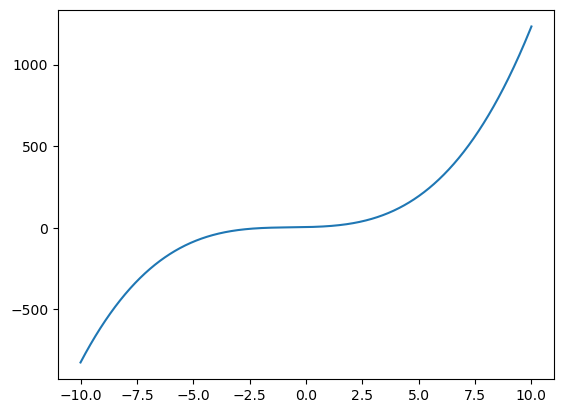

In [3]:
b = 2
c = 3
d = 4

p = Polynomial([d,c,b,1])
x = np.linspace(-10, 10, 1000)
plt.plot(x, p(x), label='P(x)')
plt.show()

### sum of roots

In [4]:
sum_vieta = -b
print(f'Sum of roots (according to Vieta\'s formulae): {sum_vieta}')

Sum of roots (according to Vieta's formulae): -2


In [5]:
# manual

roots=p.roots()
print(roots)
sum_calc = np.sum(roots)

[-1.65062919+0.j         -0.1746854 -1.54686889j -0.1746854 +1.54686889j]


In [6]:
# error = predicted - calculated
error_sum = sum_vieta - sum_calc
print(error_sum)

(8.881784197001252e-16+0j)


### pairwise products

In [7]:
pair_products_calc = 0

for j in combinations (roots, 2):
    pair_products_calc = pair_products_calc + np.prod(j)

print(pair_products_calc)

pair_products_vieta = c
error_pair_products = pair_products_vieta - pair_products_calc
print(error_pair_products)

(2.999999999999999+0j)
(8.881784197001252e-16+0j)


### product of roots

In [8]:
product = np.prod(roots)

product_vieta = -d

error_product = product_vieta - product
print(error_product)

(-4.440892098500626e-16+0j)


### analysis

In [9]:
total_error = abs(error_sum) + abs(error_pair_products) + abs(error_product)
print(total_error)

# that's practically zero, but how does it compare to different coefficients for the same polynomial?

2.220446049250313e-15


## level 2: automation

In [10]:
# explotation objective: we've visualised and confirmed vieta's formulae, and we've identified that there is an error, though it is minute. does that error change with the coefficents? if so, how?
# to check that, we need a dataset. so, we need to code a faster way to calculate the relevant quantities

In [11]:
data = []

In [12]:
def test_vieta():
    a = float(input("Please enter the coefficient of x\u00b3."))
    while a == 0:
        print("Please enter a non-zero real value.")
        a = float(input("Please enter the coefficient of x\u00b3."))
    b = float(input("Please enter the coefficient of x\u00b2."))
    c = float(input("Please enter the coefficient of x."))
    d = float(input("Please enter the constant value."))
    p = Polynomial([d,c,b,a])
    # sum of roots
    predicted_sum = -b/a
    roots=p.roots()
    calculated_sum = np.sum(roots)
    error_sum = predicted_sum - calculated_sum
    # pairwise products
    calculated_pairs = 0
    for j in combinations (roots, 2):
        calculated_pairs = calculated_pairs + np.prod(j)
    predicted_pairs = c/a
    error_pair_products = predicted_pairs - calculated_pairs
    # product
    calculated_product = np.prod(roots)
    predicted_product = -d/a
    error_product = predicted_product - calculated_product
    #total error
    total_error = abs(error_sum) + abs(error_pair_products) + abs(error_product)
    #enter data into an array
    results = [a, b, c, d, float(error_sum), float(error_pair_products), float(error_product), float(total_error)]
    data.append(results)
    return results

In [13]:
# running my iterations and commenting the code out
# test_vieta() # coeffs 1, -6, 11, -6; three distinct real roots
# test_vieta() # coeffs 1, 0, 1, 1; one real root, two complex roots
# test_vieta() # coeffs 1, 0, -3, 2; repeated roots
# test_vieta() # coeffs 2, -4, -10, 12; non monic cubic

In [14]:
# used this to check my list, commenting the code out
# print(data)

In [15]:
# creating the dataframe, commenting the code out
# df = pd.DataFrame(data, columns=[
    # "a", "b", "c", "d", "error_sum", "error_pairs", "error_product", "total_error"])

# Source - https://stackoverflow.com/a/24284680
# Posted by Piotr Migdal, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-10, License - CC BY-SA 4.0
# adding the first experiment

# df.loc[-1] = [1, 1, 1, 1, complex(8.881784197001252e-16+0j), complex(8.881784197001252e-16+0j), complex(-4.440892098500626e-16+0j), float(2.220446049250313e-15)]  # adding a row
# df.index = df.index + 1  # shifting index
# df = df.sort_index()  # sorting by index


# df.to_csv("vieta_experiments.csv", index=False)

In [16]:
# saved the data, now open the dataframe
df = pd.read_csv("vieta_experiments.csv")
df

,a,b,c,d,error_sum,error_pairs,error_product,total_error
0,(1+0j),(1+0j),(1+0j),(1+0j),(8.881784197001252e-16+0j),(8.881784197001252e-16+0j),(-4.440892098500626e-16+0j),(2.220446049250313e-15+0j)
1,(1+0j),(-6+0j),(11+0j),(-6+0j),0j,(5.329070518200751e-15+0j),(5.329070518200751e-15+0j),(1.0658141036401503e-14+0j)
2,(1+0j),0j,(1+0j),(1+0j),(-4.440892098500626e-16+0j),(-2.6645352591003757e-15+0j),(1.3322676295501878e-15+0j),(4.440892098500626e-15+0j)
3,(1+0j),0j,(-3+0j),(2+0j),(-2.220446049250313e-16+0j),(-2.6645352591003757e-15+0j),(-2.886579864025407e-15+0j),(5.773159728050814e-15+0j)
4,(2+0j),(-4+0j),(-10+0j),(12+0j),(8.881784197001252e-16+0j),(3.552713678800501e-15+0j),(7.993605777301127e-15+0j),(1.2434497875801753e-14+0j)


## level 3: analyse the preliminary data

In [17]:
# exploration objective: we have a small dataset. now, we make a preliminary exploration on how the coefficients of a cubic polynomial affect 
# the numerical accuracy of the sums calculated by python, with vieta's formulae as a baseline

In [21]:
# need all the dataframe values as float numbers
df = df.astype(complex)
df = df.astype(float)

C:\Users\DELL\anaconda3\Lib\site-packages\pandas\core\dtypes\astype.py:133: ComplexWarning: Casting complex values to real discards the imaginary part
  return arr.astype(dtype, copy=True)


In [23]:
# our errors are currently signed, create columns for absolute error
df["error_sum_abs"] = df["error_sum"].abs()
df["error_pairs_abs"] = df["error_pairs"].abs()
df["error_product_abs"] = df["error_product"].abs()

df

,a,b,c,d,error_sum,error_pairs,error_product,total_error,error_sum_abs,error_pairs_abs,error_product_abs
0,1.0,1.0,1.0,1.0,8.881784e-16,8.881784e-16,-4.440892e-16,2.220446e-15,8.881784e-16,8.881784e-16,4.440892e-16
1,1.0,-6.0,11.0,-6.0,0.000000e+00,5.329071e-15,5.329071e-15,1.065814e-14,0.000000e+00,5.329071e-15,5.329071e-15
2,1.0,0.0,1.0,1.0,-4.440892e-16,-2.664535e-15,1.332268e-15,4.440892e-15,4.440892e-16,2.664535e-15,1.332268e-15
3,1.0,0.0,-3.0,2.0,-2.220446e-16,-2.664535e-15,-2.886580e-15,5.773160e-15,2.220446e-16,2.664535e-15,2.886580e-15
4,2.0,-4.0,-10.0,12.0,8.881784e-16,3.552714e-15,7.993606e-15,1.243450e-14,8.881784e-16,3.552714e-15,7.993606e-15


In [24]:
# create a dictionary with the relevant data

mean_errors = {'sum':float(df["error_sum_abs"].mean()), 'pairs':float(df["error_pairs_abs"].mean()), 'product':float(df["error_product_abs"].mean())}
print(mean_errors)

median_errors = {'sum':float(df["error_sum_abs"].median()), 'pairs':float(df["error_pairs_abs"].median()), 'product':float(df["error_product_abs"].median())}
print(median_errors)

max_errors = {'sum':float(df["error_sum_abs"].max()), 'pairs':float(df["error_pairs_abs"].max()), 'product':float(df["error_product_abs"].max())}
print(max_errors)

std_errors = {'sum':float(df["error_sum_abs"].std()), 'pairs':float(df["error_pairs_abs"].std()), 'product':float(df["error_product_abs"].std())}
print(std_errors)

{'sum': 4.884981308350689e-16, 'pairs': 3.0198066269804257e-15, 'product': 3.597122599785507e-15}
{'sum': 4.440892098500626e-16, 'pairs': 2.6645352591003757e-15, 'product': 2.886579864025407e-15}
{'sum': 8.881784197001252e-16, 'pairs': 5.329070518200751e-15, 'product': 7.993605777301127e-15}
{'sum': 3.9720546451956367e-16, 'pairs': 1.6134562241441008e-15, 'product': 3.0783423500266184e-15}


Text(0.5, 1.0, 'Mean Absolute Errors Across the Vieta Relationships')

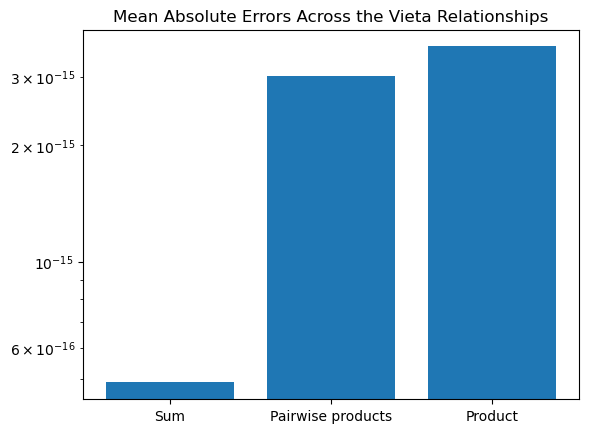

In [25]:
# let's compare the means

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_errors['sum'], mean_errors['pairs'], mean_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Absolute Errors Across the Vieta Relationships')

In [29]:
# let's check mean relative errors 
df['relative_error_sum_abs'] = df['error_sum_abs'] / (df['b'].abs() / df['a'].abs())
df.loc[(df['a']==0)|(df["b"])==0, 'relative_error_sum_abs'] = np.nan

df['relative_error_pairs_abs'] = df['error_pairs_abs'] / (df['c'].abs() / df['a'].abs())
df.loc[(df['a']==0)|(df["c"])==0, 'relative_error_pairs_abs'] = np.nan

df['relative_error_product_abs'] = df['error_product_abs'] / (df['d'].abs() / df['a'].abs())
df.loc[(df['a']==0)|(df["d"])==0, 'relative_error_product_abs'] = np.nan

mean_relative_errors = {'sum':float(df["relative_error_sum_abs"].mean()), 'pairs':float(df["relative_error_pairs_abs"].mean()), 'product':float(df["relative_error_product_abs"].mean())}
print(mean_errors)

df

{'sum': 4.884981308350689e-16, 'pairs': 3.0198066269804257e-15, 'product': 3.597122599785507e-15}


,a,b,c,d,error_sum,error_pairs,error_product,total_error,error_sum_abs,error_pairs_abs,error_product_abs,relative_error_sum_abs,relative_error_pairs_abs,relative_error_product_abs
0,1.0,1.0,1.0,1.0,8.881784e-16,8.881784e-16,-4.440892e-16,2.220446e-15,8.881784e-16,8.881784e-16,4.440892e-16,8.881784e-16,8.881784e-16,4.440892e-16
1,1.0,-6.0,11.0,-6.0,0.000000e+00,5.329071e-15,5.329071e-15,1.065814e-14,0.000000e+00,5.329071e-15,5.329071e-15,0.000000e+00,4.844610e-16,8.881784e-16
2,1.0,0.0,1.0,1.0,-4.440892e-16,-2.664535e-15,1.332268e-15,4.440892e-15,4.440892e-16,2.664535e-15,1.332268e-15,NaN,2.664535e-15,1.332268e-15
3,1.0,0.0,-3.0,2.0,-2.220446e-16,-2.664535e-15,-2.886580e-15,5.773160e-15,2.220446e-16,2.664535e-15,2.886580e-15,NaN,8.881784e-16,1.443290e-15
4,2.0,-4.0,-10.0,12.0,8.881784e-16,3.552714e-15,7.993606e-15,1.243450e-14,8.881784e-16,3.552714e-15,7.993606e-15,4.440892e-16,7.105427e-16,1.332268e-15


Text(0.5, 1.0, 'Mean Relative Errors Across the Vieta Relationships')

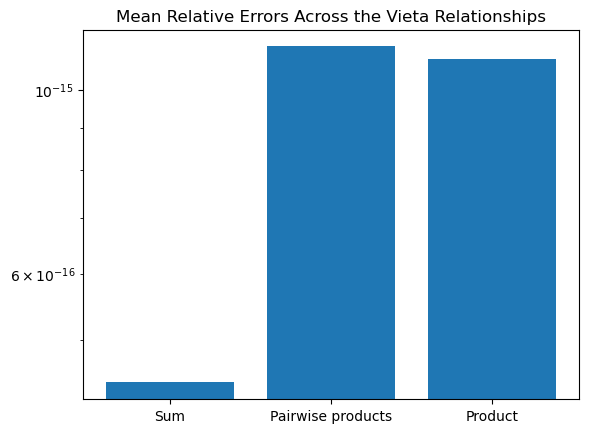

In [31]:
# graph mean relative errors

x = ['Sum', 'Pairwise products', 'Product']
y = [mean_relative_errors['sum'], mean_relative_errors['pairs'], mean_relative_errors['product']]
plt.bar(x, y)
plt.yscale('log')
plt.title('Mean Relative Errors Across the Vieta Relationships')

In [32]:
# sum appears to have the smallest error (probably because it involves the least operations so the least rounding by python)
# to test that, we need a much larger dataset

## level 4: expansion

In [33]:
# exploration objective: we believe that sum has the smallest error, whether relative or absolute. now, we need a larger dataset to test that

In [37]:
data = np.empty(shape=(1000,1))
df2 = pd.DataFrame(data)

for i in range(200)
    coeffs = random.sample(range(-10, 11), 3)
    p = Polynomial(coeffs)
    
    

IndentationError: unexpected indent (1137716258.py, line 3)